<a href="https://colab.research.google.com/github/uranovnass/Machine-Learning/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Размер данных: (300, 2)
Количество классов: 2

--- Линейное ядро ---
Accuracy: 0.7833333333333333


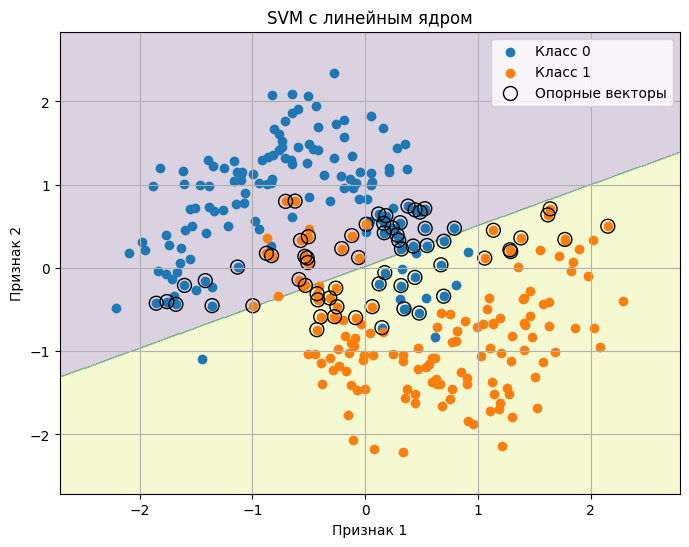


--- RBF ядро ---
Accuracy: 0.8666666666666667


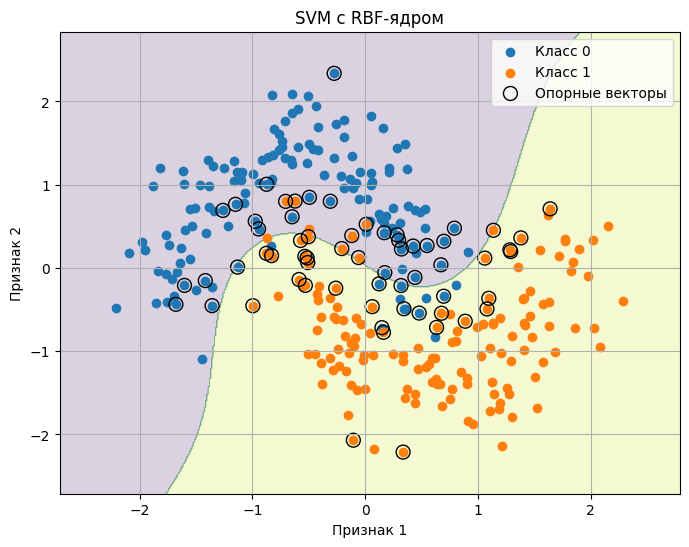


СРАВНЕНИЕ
Linear accuracy: 0.7833
RBF accuracy:    0.8667

--- RBF, C = 10 ---
Accuracy: 0.9666666666666667


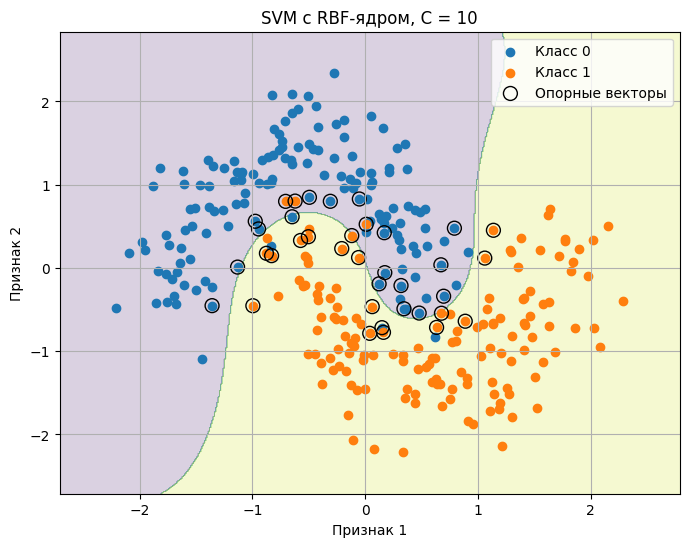


ВЛИЯНИЕ ПАРАМЕТРА C
RBF, C=1  : 0.8667
RBF, C=10 : 0.9667


In [1]:
# Практическая работа №9
# Метод опорных векторов (SVM)

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report


# ============================================================
# 1. Создание двумерного датасета
# ============================================================

X, y = make_moons(
    n_samples=300,
    noise=0.2,
    random_state=42
)

print("Размер данных:", X.shape)
print("Количество классов:", len(np.unique(y)))


# ============================================================
# 2. Масштабирование признаков
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================================
# 3. Деление на обучающую и тестовую выборки
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ============================================================
# Функция для построения границы решения
# ============================================================

def plot_decision_boundary(model, X, y, title):
    x_min = X[:, 0].min() - 0.5
    x_max = X[:, 0].max() + 0.5
    y_min = X[:, 1].min() - 0.5
    y_max = X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 500),
        np.linspace(y_min, y_max, 500)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = model.predict(grid)
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx,
        yy,
        Z,
        alpha=0.2
    )

    plt.scatter(
        X[y == 0, 0],
        X[y == 0, 1],
        label="Класс 0"
    )

    plt.scatter(
        X[y == 1, 0],
        X[y == 1, 1],
        label="Класс 1"
    )

    # Опорные векторы
    if hasattr(model, "support_vectors_"):
        plt.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=100,
            facecolors="none",
            edgecolors="black",
            label="Опорные векторы"
        )

    plt.title(title)
    plt.xlabel("Признак 1")
    plt.ylabel("Признак 2")
    plt.legend()
    plt.grid(True)
    plt.show()


# ============================================================
# 4. SVM с линейным ядром
# ============================================================

svm_linear = SVC(
    kernel="linear",
    C=1
)

svm_linear.fit(X_train, y_train)

y_pred_linear = svm_linear.predict(X_test)

print("\n--- Линейное ядро ---")
print("Accuracy:", accuracy_score(y_test, y_pred_linear))

plot_decision_boundary(
    svm_linear,
    X_scaled,
    y,
    "SVM с линейным ядром"
)


# ============================================================
# 5. SVM с RBF-ядром
# ============================================================

svm_rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)

print("\n--- RBF ядро ---")
print("Accuracy:", accuracy_score(y_test, y_pred_rbf))

plot_decision_boundary(
    svm_rbf,
    X_scaled,
    y,
    "SVM с RBF-ядром"
)


# ============================================================
# 6. Сравнение результатов
# ============================================================

print("\n================================")
print("СРАВНЕНИЕ")
print("================================")

print(
    f"Linear accuracy: {accuracy_score(y_test, y_pred_linear):.4f}"
)

print(
    f"RBF accuracy:    {accuracy_score(y_test, y_pred_rbf):.4f}"
)


# ============================================================
# 7. Изменение параметра C
# ============================================================

svm_rbf_C10 = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

svm_rbf_C10.fit(X_train, y_train)

y_pred_C10 = svm_rbf_C10.predict(X_test)

print("\n--- RBF, C = 10 ---")
print("Accuracy:", accuracy_score(y_test, y_pred_C10))

plot_decision_boundary(
    svm_rbf_C10,
    X_scaled,
    y,
    "SVM с RBF-ядром, C = 10"
)


# ============================================================
# 8. Сравнение C = 1 и C = 10
# ============================================================

print("\n================================")
print("ВЛИЯНИЕ ПАРАМЕТРА C")
print("================================")

print(
    f"RBF, C=1  : {accuracy_score(y_test, y_pred_rbf):.4f}"
)

print(
    f"RBF, C=10 : {accuracy_score(y_test, y_pred_C10):.4f}"
)